# SlumberWell — Phase 1: ML Experimentation (full dataset)
**Sleep stage classification with traditional machine learning (Sleep-EDF Expanded, Sleep Cassette, all subjects)**

Pipeline:

1. Load PSG + hypnogram EDFs → band-pass → 30 s epochs → labels (W, N1, N2, N3, REM)
2. 16 handcrafted features per epoch (statistical, band power, relative power, spectral entropy)
3. **Subject-wise** train / validation / test split (both nights of a subject stay together)
4. **Feature ablation** on validation: raw features vs per-recording z-score vs z-score + neighbouring-epoch context
5. Compare Random Forest, Extra Trees, XGBoost, SVM, HistGradientBoosting against a majority baseline
6. Tune the strongest candidates, select by **validation macro F1**, evaluate **once** on test
7. Export artifacts for the FastAPI backend

Data: the 150 recordings already downloaded into `data/sleep-cassette/` (no download step needed).
Tip: set `N_SUBJECTS = 20` in the config for a quick end-to-end smoke test, then back to `None` for the full run.

## 0. Setup

In [ ]:
%pip install -q mne xgboost scikit-learn scipy pandas matplotlib seaborn joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.2.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import json, time, platform, warnings, random, hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import mne, sklearn, scipy, xgboost

from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.model_selection import ParameterSampler
from sklearn.metrics import (accuracy_score, f1_score, recall_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report, cohen_kappa_score)
from xgboost import XGBClassifier

mne.set_log_level("ERROR")
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="Channels contain different")     # harmless EDF header notes
warnings.filterwarnings("ignore", message="Highpass cutoff")
sns.set_theme(style="whitegrid")

## 1. Configuration
Everything that affects results lives here. `SEED` drives the split and every model.

In [ ]:
SEED = 42
random.seed(SEED); np.random.seed(SEED)

# --- data -------------------------------------------------------------------
DATA_DIR   = Path("data/sleep-cassette")   # folder holding the SC*-PSG.edf and SC*-Hypnogram.edf files
N_SUBJECTS = None                          # None = every subject found (full run); e.g. 20 for a quick smoke test

# --- paths ------------------------------------------------------------------
ARTIFACT_DIR = Path("artifacts");  ARTIFACT_DIR.mkdir(exist_ok=True)
CACHE_DIR    = Path("cache");      CACHE_DIR.mkdir(exist_ok=True)

# --- experiment switches ----------------------------------------------------
TRIM_WAKE       = True     # limit wake to +/- WAKE_MARGIN_MIN around sleep (recordings contain many hours of wake)
WAKE_MARGIN_MIN = 30
APPLY_QUALITY   = True     # drop flat / extreme-amplitude epochs
FLAT_STD_UV     = 1.0
FEATURE_VARIANT = None     # None = choose the best variant of section 9 by validation macro F1; or "A_raw" / "B_zscore" / "C_zscore_context"
REFIT_TRAIN_VAL = True     # refit the chosen model on train + validation subjects before the one-shot test
N_TUNING_TRIALS = 6        # random draws per tuned model (lower = faster)
TUNE_TOP_K      = 2        # tune the K best default models (Random Forest and XGBoost are always included)
SVM_MAX_TRAIN   = 20000    # SVC is O(n^2); random subsample of train for SVM only

## 2. Shared core module
Preprocessing, epoching, labelling, feature code **and the per-recording normalisation / context transform** are written to
`slumberwell_core.py` and **imported**, so the backend can use the exact same file (no training/serving skew).
Copy this file into the backend package.

In [ ]:
%%writefile slumberwell_core.py
"""SlumberWell shared core: preprocessing, epoching, labelling and feature extraction.

Imported by BOTH the training notebook and the FastAPI backend so that training
and inference produce identical features (no training/serving skew).
"""
from __future__ import annotations

import re
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.integrate import trapezoid
from scipy.signal import butter, resample_poly, sosfiltfilt, welch

# --------------------------------------------------------------------------- #
# Labels (spec section 4.4)
# --------------------------------------------------------------------------- #
STAGE_NAMES = ["W", "N1", "N2", "N3", "REM"]
LABEL_TO_INT = {name: i for i, name in enumerate(STAGE_NAMES)}
INT_TO_LABEL = {i: name for name, i in LABEL_TO_INT.items()}

# Hypnogram annotation text -> SlumberWell stage. Movement / unscored are absent
# on purpose: they are excluded, never treated as a sleep stage.
ANNOTATION_MAP = {
    "Sleep stage W": "W",
    "Sleep stage 1": "N1",
    "Sleep stage 2": "N2",
    "Sleep stage 3": "N3",
    "Sleep stage 4": "N3",   # stages 3 + 4 merged (AASM convention)
    "Sleep stage R": "REM",
}

DEFAULT_CONFIG = {
    "channels": ["EEG Fpz-Cz"],
    "sampling_rate_hz": 100,
    "bandpass_hz": [0.3, 35.0],
    "filter_order": 4,
    "epoch_length_sec": 30,
    "welch": {"window_sec": 4, "overlap": 0.5},
    "bands_hz": {"delta": [0.5, 4.0], "theta": [4.0, 8.0],
                 "alpha": [8.0, 13.0], "beta": [13.0, 30.0]},
    "total_power_range_hz": [0.5, 30.0],
    "min_duration_epochs": 10,
    # training-only parameters (filled in by the notebook, stored for the record)
    "wake_margin_min": 30,
    "quality": {"flat_std_uv": 0.1, "max_abs_uv": None},
}


# --------------------------------------------------------------------------- #
# File-name helpers (spec section 4.2)
# --------------------------------------------------------------------------- #
def parse_sc_name(path) -> dict:
    """SC4ssNE0-PSG.edf -> subject number ss and night N."""
    name = Path(path).name
    m = re.match(r"SC4(\d{2})(\d)", name)
    if not m:
        raise ValueError(f"Not a Sleep Cassette file name: {name}")
    return {"subject": int(m.group(1)), "night": int(m.group(2))}


def find_hypnogram(psg_path) -> Path | None:
    """SC4001E0-PSG.edf -> SC4001E?-Hypnogram.edf in the same folder."""
    psg_path = Path(psg_path)
    prefix = psg_path.name.split("-")[0][:7]          # e.g. SC4001E
    hits = sorted(psg_path.parent.glob(f"{prefix}*-Hypnogram.edf"))
    return hits[0] if hits else None


# --------------------------------------------------------------------------- #
# Signal loading and preprocessing (spec section 5, steps 1, 3, 4, 5)
# --------------------------------------------------------------------------- #
def read_edf(path, channels, verbose=False):
    """Read an EDF with MNE and return (signals_uV [n_ch, n_samples], sfreq, raw)."""
    import mne  # imported lazily so the module can be imported without MNE
    raw = mne.io.read_raw_edf(str(path), preload=False, verbose=verbose)
    missing = [c for c in channels if c not in raw.ch_names]
    if missing:
        raise KeyError(f"Channel(s) {missing} not found. Available channels: {raw.ch_names}")
    raw.pick(channels)
    raw.load_data(verbose=verbose)
    return raw.get_data() * 1e6, raw.info["sfreq"], raw      # volts -> microvolts


def resample_to(x, sfreq, target_sfreq):
    """Resample along the last axis to target_sfreq (no-op if already equal)."""
    if abs(sfreq - target_sfreq) < 1e-6:
        return x
    from fractions import Fraction
    frac = Fraction(target_sfreq / sfreq).limit_denominator(1000)
    return resample_poly(x, frac.numerator, frac.denominator, axis=-1)


def bandpass(x, fs, low, high, order=4):
    sos = butter(order, [low, high], btype="band", fs=fs, output="sos")
    return sosfiltfilt(sos, x, axis=-1)


def make_epochs(x, fs, epoch_len_sec=30):
    """Cut [n_ch, n_samples] into non-overlapping epochs [n_epochs, n_ch, n_per_epoch].
    An incomplete final epoch is discarded (FR-03)."""
    n = int(round(epoch_len_sec * fs))
    n_epochs = x.shape[-1] // n
    x = x[..., : n_epochs * n]
    return x.reshape(x.shape[0], n_epochs, n).transpose(1, 0, 2)


def preprocess_signal(path, cfg):
    """EDF path -> epochs [n_epochs, n_ch, samples] in uV (resampled, band-passed)."""
    x, sfreq, raw = read_edf(path, cfg["channels"])
    fs = cfg["sampling_rate_hz"]
    x = resample_to(x, sfreq, fs)
    x = bandpass(x, fs, *cfg["bandpass_hz"], order=cfg.get("filter_order", 4))
    return make_epochs(x, fs, cfg["epoch_length_sec"]), raw


# --------------------------------------------------------------------------- #
# Labels from a hypnogram (spec section 5, step 6)
# --------------------------------------------------------------------------- #
def epoch_labels_from_annotations(onsets, durations, descriptions, n_epochs, epoch_len=30):
    """Return int array [n_epochs]; -1 = excluded (movement, unscored, uncovered).
    An epoch is labelled only if it lies entirely inside one mapped annotation."""
    labels = np.full(n_epochs, -1, dtype=int)
    eps = 1e-6
    for onset, dur, desc in zip(onsets, durations, descriptions):
        stage = ANNOTATION_MAP.get(str(desc).strip())
        if stage is None:
            continue
        first = int(np.ceil((onset - eps) / epoch_len))
        last = int(np.floor((onset + dur + eps) / epoch_len))   # exclusive
        first, last = max(first, 0), min(last, n_epochs)
        if last > first:
            labels[first:last] = LABEL_TO_INT[stage]
    return labels


def read_hypnogram(hyp_path, raw):
    """Read hypnogram annotations; return onsets relative to the PSG start."""
    import mne
    ann = mne.read_annotations(str(hyp_path))
    onsets = np.asarray(ann.onset, dtype=float)
    if ann.orig_time is not None and raw.info["meas_date"] is not None:
        onsets = onsets + (ann.orig_time - raw.info["meas_date"]).total_seconds()
    return onsets, np.asarray(ann.duration, dtype=float), list(ann.description)


def trim_wake_mask(labels, margin_epochs):
    """Keep wake only within margin_epochs before the first / after the last sleep epoch."""
    sleep_idx = np.where(labels > LABEL_TO_INT["W"])[0]
    keep = np.zeros(len(labels), dtype=bool)
    if len(sleep_idx) == 0:
        return keep
    lo = max(sleep_idx[0] - margin_epochs, 0)
    hi = min(sleep_idx[-1] + margin_epochs + 1, len(labels))
    keep[lo:hi] = True
    return keep


# --------------------------------------------------------------------------- #
# Feature engineering (spec section 6): 16 features per channel
# --------------------------------------------------------------------------- #
BASE_FEATURES = (
    ["mean", "std", "var", "rms", "min", "max", "range"]
    + ["delta_power", "theta_power", "alpha_power", "beta_power"]
    + ["rel_delta", "rel_theta", "rel_alpha", "rel_beta"]
    + ["spectral_entropy"]
)


def feature_names(cfg) -> list[str]:
    chs = cfg["channels"]
    if len(chs) == 1:
        return list(BASE_FEATURES)
    safe = [c.replace(" ", "_").replace("-", "_") for c in chs]
    return [f"{c}__{f}" for c in safe for f in BASE_FEATURES]


def _channel_features(ep, cfg):
    """ep: [n_epochs, samples] -> dict of feature arrays [n_epochs]."""
    fs = cfg["sampling_rate_hz"]
    f = {}
    f["mean"] = ep.mean(axis=1)
    f["std"] = ep.std(axis=1)
    f["var"] = ep.var(axis=1)
    f["rms"] = np.sqrt((ep ** 2).mean(axis=1))
    f["min"] = ep.min(axis=1)
    f["max"] = ep.max(axis=1)
    f["range"] = f["max"] - f["min"]

    nperseg = int(cfg["welch"]["window_sec"] * fs)
    noverlap = int(nperseg * cfg["welch"]["overlap"])
    freqs, psd = welch(ep, fs=fs, nperseg=nperseg, noverlap=noverlap, axis=-1)

    def band_power(lo, hi):
        m = (freqs >= lo) & (freqs <= hi)
        return trapezoid(psd[:, m], freqs[m], axis=1)

    bands = {k: band_power(*v) for k, v in cfg["bands_hz"].items()}
    tlo, thi = cfg["total_power_range_hz"]
    total = band_power(tlo, thi)
    for k in ("delta", "theta", "alpha", "beta"):
        f[f"{k}_power"] = bands[k]
        f[f"rel_{k}"] = bands[k] / np.maximum(total, 1e-12)

    m = (freqs >= tlo) & (freqs <= thi)
    p = psd[:, m]
    p = p / np.maximum(p.sum(axis=1, keepdims=True), 1e-12)
    ent = -(p * np.log2(np.maximum(p, 1e-12))).sum(axis=1)
    f["spectral_entropy"] = ent / np.log2(p.shape[1])          # normalised to 0..1
    return f


def extract_features(epochs, cfg) -> pd.DataFrame:
    """epochs [n_epochs, n_ch, samples] -> DataFrame with columns in feature_names(cfg) order."""
    cols = {}
    names = feature_names(cfg)
    k = 0
    for ch in range(epochs.shape[1]):
        feats = _channel_features(epochs[:, ch, :], cfg)
        for base in BASE_FEATURES:
            cols[names[k]] = feats[base]
            k += 1
    return pd.DataFrame(cols, columns=names)


# --------------------------------------------------------------------------- #
# End-to-end helpers
# --------------------------------------------------------------------------- #
def featurize_recording(psg_path, hyp_path, cfg, subject_id=None, recording_id=None):
    """TRAINING path: PSG + hypnogram -> labelled feature table (before wake trimming)."""
    epochs, raw = preprocess_signal(psg_path, cfg)
    feats = extract_features(epochs, cfg)
    onsets, durs, descs = read_hypnogram(hyp_path, raw)
    labels = epoch_labels_from_annotations(onsets, durs, descs, len(feats), cfg["epoch_length_sec"])
    meta = pd.DataFrame({
        "subject_id": subject_id,
        "recording_id": recording_id or Path(psg_path).name.split("-")[0],
        "epoch_index": np.arange(len(feats)),
        "label": labels,
    })
    return pd.concat([meta, feats], axis=1)


def featurize_edf(path, cfg) -> pd.DataFrame:
    """INFERENCE path: EDF only -> feature matrix. Epochs start at time zero."""
    epochs, _ = preprocess_signal(path, cfg)
    if len(epochs) < cfg.get("min_duration_epochs", 1):
        raise ValueError(f"Recording too short: {len(epochs)} complete epochs.")
    return extract_features(epochs, cfg)


def summarize_predictions(stages, epoch_len_sec=30) -> dict:
    """Summary sleep metrics from predicted stage names (spec section 2.5)."""
    stages = np.asarray(stages)
    n = len(stages)
    mins = epoch_len_sec / 60.0
    trt = n * mins
    asleep = stages != "W"
    tst = asleep.sum() * mins
    onset = int(np.argmax(asleep)) if asleep.any() else None
    rem_idx = np.where(stages == "REM")[0]
    rem_lat = None
    if onset is not None and len(rem_idx):
        rem_lat = float((rem_idx[0] - onset) * mins)
    counts = {s: int((stages == s).sum()) for s in STAGE_NAMES}
    return {
        "total_recording_min": trt,
        "total_sleep_min": float(tst),
        "sleep_efficiency_pct": float(100 * tst / trt) if trt else 0.0,
        "sleep_onset_latency_min": None if onset is None else float(onset * mins),
        "rem_latency_min": rem_lat,
        "stage_counts": counts,
        "stage_percent": {s: float(100 * c / n) if n else 0.0 for s, c in counts.items()},
    }


# --------------------------------------------------------------------------- #
# Recording-level feature transforms (identical in training and serving)
# --------------------------------------------------------------------------- #
CONTEXT_BASE = ["std", "rel_delta", "rel_theta", "rel_alpha", "rel_beta", "spectral_entropy"]
CONTEXT_SHIFTS = (1, 2)      # previous / next 1 and 2 epochs (30 s and 60 s on either side)


def _context_source_cols(cfg):
    return [n for n in feature_names(cfg) if n.split("__")[-1] in CONTEXT_BASE]


def model_feature_names(cfg) -> list[str]:
    """Columns the model sees: base features (+ neighbouring-epoch context if enabled)."""
    names = list(feature_names(cfg))
    if cfg.get("context_epochs"):
        for c in _context_source_cols(cfg):
            for k in CONTEXT_SHIFTS:
                names += [f"{c}_prev{k}", f"{c}_next{k}"]
    return names


def add_recording_features(feats: pd.DataFrame, cfg: dict) -> pd.DataFrame:
    """feats = ONE recording's epochs in time order (needs the feature_names(cfg) columns).

    1) cfg["normalize_per_recording"]: z-score every feature within the recording, which removes
       person-to-person amplitude differences (the main cross-subject problem for EEG features).
    2) cfg["context_epochs"]: add the previous / next epochs' values of a few key features,
       because sleep stages last minutes, not 30 s.
    """
    out = feats.copy()
    names = feature_names(cfg)
    if cfg.get("normalize_per_recording"):
        x = out[names].astype(float)
        out[names] = (x - x.mean()) / (x.std(ddof=0) + 1e-8)
    if cfg.get("context_epochs"):
        src = _context_source_cols(cfg)
        new = {}
        for k in CONTEXT_SHIFTS:
            prev = out[src].shift(k).fillna(out[src])       # edges: fall back to the epoch itself
            nxt = out[src].shift(-k).fillna(out[src])
            for c in src:
                new[f"{c}_prev{k}"] = prev[c]
                new[f"{c}_next{k}"] = nxt[c]
        out = pd.concat([out, pd.DataFrame(new, index=out.index)], axis=1)
    return out

Overwriting slumberwell_core.py


In [ ]:
import importlib, slumberwell_core as sw
importlib.reload(sw)
CFG = json.loads(json.dumps(sw.DEFAULT_CONFIG))          # deep copy of the spec defaults
CFG["wake_margin_min"] = WAKE_MARGIN_MIN if TRIM_WAKE else None
CFG["quality"] = {"flat_std_uv": FLAT_STD_UV, "max_abs_uv": None}   # max_abs_uv is learned from the training split
CFG["normalize_per_recording"] = False                   # set by the variant chosen in section 9
CFG["context_epochs"] = False
print(json.dumps(CFG, indent=2))

{
  "channels": [
    "EEG Fpz-Cz"
  ],
  "sampling_rate_hz": 100,
  "bandpass_hz": [
    0.3,
    35.0
  ],
  "filter_order": 4,
  "epoch_length_sec": 30,
  "welch": {
    "window_sec": 4,
    "overlap": 0.5
  },
  "bands_hz": {
    "delta": [
      0.5,
      4.0
    ],
    "theta": [
      4.0,
      8.0
    ],
    "alpha": [
      8.0,
      13.0
    ],
    "beta": [
      13.0,
      30.0
    ]
  },
  "total_power_range_hz": [
    0.5,
    30.0
  ],
  "min_duration_epochs": 10,
  "wake_margin_min": 30,
  "quality": {
    "flat_std_uv": 1.0,
    "max_abs_uv": null
  },
  "normalize_per_recording": false,
  "context_epochs": false
}


## 3. Find the recordings
The full Sleep Cassette set is already on disk, so this only pairs every `SC4ssN?-PSG.edf` with its hypnogram.

In [ ]:
def list_recordings(data_dir=DATA_DIR, n_subjects=N_SUBJECTS):
    psg_files = sorted(data_dir.glob("SC*-PSG.edf"))
    hyp_files = sorted(data_dir.glob("SC*-Hypnogram.edf"))
    print(f"Found {len(psg_files)} PSG and {len(hyp_files)} hypnogram files in {data_dir.resolve()}")
    if not psg_files:
        raise FileNotFoundError(f"No SC*-PSG.edf files in {data_dir.resolve()}. Check DATA_DIR.")

    hyp_by_id = {}
    for h in hyp_files:
        rid = h.name[:6]                                   # SC4001
        if rid in hyp_by_id:
            raise ValueError(f"Duplicate hypnogram for {rid}: {hyp_by_id[rid].name} and {h.name}")
        hyp_by_id[rid] = h

    rows = []
    for p in psg_files:
        rid = p.name[:6]
        h = hyp_by_id.get(rid)
        if h is None:
            print(f"Warning: no hypnogram for {p.name}"); continue
        rows.append({"psg": p, "hyp": h, "subject": int(p.name[3:5]), "night": int(p.name[5]), "recording_id": rid})

    out = pd.DataFrame(rows).sort_values(["subject", "night"]).reset_index(drop=True)
    if n_subjects is not None:
        keep = sorted(out["subject"].unique())[:n_subjects]
        out = out[out["subject"].isin(keep)].reset_index(drop=True)
    print(f"Using {len(out)} recordings from {out['subject'].nunique()} subjects")
    print("Nights per subject:", out.groupby("subject").size().value_counts().to_dict())
    return out

recordings = list_recordings()
recordings[["recording_id", "subject", "night"]].head()

Found 150 PSG and 150 hypnogram files in C:\Users\TANVI\Downloads\ML project\data\sleep-cassette
Using 150 recordings from 77 subjects
Nights per subject: {2: 73, 1: 4}


,recording_id,subject,night
0,SC4001,0,1
1,SC4002,0,2
2,SC4011,1,1
3,SC4012,1,2
4,SC4021,2,1


## 4. Dataset inspection
Confirm channel names and sampling rate on one recording before trusting the pipeline.

Channels: ['EEG Fpz-Cz', 'EEG Pz-Oz', 'EOG horizontal', 'Resp oro-nasal', 'EMG submental', 'Temp rectal', 'Event marker']
Sampling rate (Hz): 100.0
Duration: 22.1 h
Sleep stage 3    48
Sleep stage 2    40
Sleep stage 1    24
Sleep stage 4    23
Sleep stage W    12
Sleep stage R     6
Sleep stage ?     1
Name: count, dtype: int64


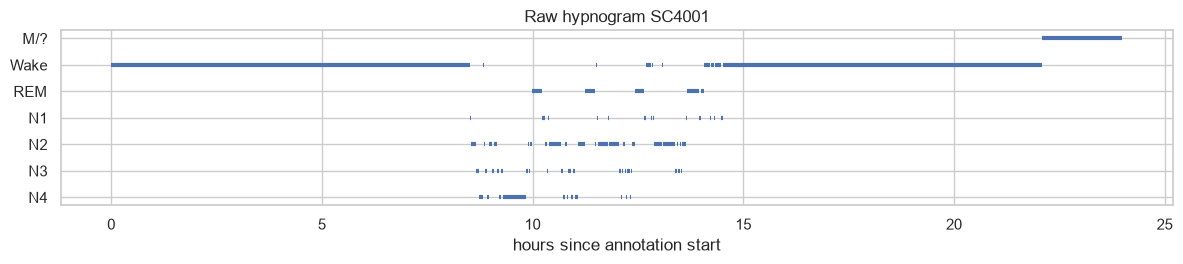

In [7]:
r0 = recordings.iloc[0]
raw0 = mne.io.read_raw_edf(r0.psg, preload=False)
print("Channels:", raw0.ch_names)
print("Sampling rate (Hz):", raw0.info["sfreq"])
print(f"Duration: {raw0.times[-1]/3600:.1f} h")
assert CFG["channels"][0] in raw0.ch_names, "Channel in CFG not found - update CFG['channels']"

ann0 = mne.read_annotations(r0.hyp)
print(pd.Series(ann0.description).value_counts())

order = {"Sleep stage W": 4, "Sleep stage R": 3, "Sleep stage 1": 2, "Sleep stage 2": 1,
         "Sleep stage 3": 0, "Sleep stage 4": -1, "Movement time": 5, "Sleep stage ?": 5}
fig, ax = plt.subplots(figsize=(12, 2.8))
for o, d, desc in zip(ann0.onset, ann0.duration, ann0.description):
    ax.hlines(order.get(desc, 5), o / 3600, (o + d) / 3600, lw=3)
ax.set_yticks([-1, 0, 1, 2, 3, 4, 5]); ax.set_yticklabels(["N4", "N3", "N2", "N1", "REM", "Wake", "M/?"])
ax.set_xlabel("hours since annotation start"); ax.set_title(f"Raw hypnogram {r0.recording_id}")
plt.tight_layout(); plt.show()

## 5. Build the epoch-level feature table
Per recording: read PSG → resample (if needed) → band-pass → 30 s epochs → 16 features → labels.
Movement-time and unscored epochs get label `-1`. Results are cached per recording (the cache key includes the signal
settings, so changing them never reuses stale files). The first full run takes a few minutes; reruns are instant.
`raw_std` and `raw_peak` keep the original amplitudes for quality screening, because the features are normalised later.

In [8]:
def cfg_hash(cfg):
    keys = ["channels", "sampling_rate_hz", "bandpass_hz", "filter_order", "epoch_length_sec",
            "welch", "bands_hz", "total_power_range_hz"]
    return hashlib.md5(json.dumps({k: cfg.get(k) for k in keys}, sort_keys=True).encode()).hexdigest()[:8]

def build_raw_feature_table(recordings, cfg):
    tag, tables, log, failed = cfg_hash(cfg), [], [], []
    t_start = time.time()
    for i, r in enumerate(recordings.itertuples(), 1):
        cache = CACHE_DIR / f"{r.recording_id}_{tag}.csv"
        t0 = time.time()
        try:
            if cache.exists():
                tbl = pd.read_csv(cache)
            else:
                tbl = sw.featurize_recording(r.psg, r.hyp, cfg, subject_id=r.subject, recording_id=r.recording_id)
                tbl.to_csv(cache, index=False)
        except Exception as e:                              # one bad file must not kill a 150-file run
            failed.append((r.recording_id, repr(e)[:150])); continue
        tables.append(tbl)
        log.append((r.recording_id, len(tbl), round(time.time() - t0, 1)))
        if i % 10 == 0 or i == len(recordings):
            print(f"  {i}/{len(recordings)} recordings  ({time.time() - t_start:.0f} s)")
    if failed:
        print("FAILED recordings:", failed)
    return pd.concat(tables, ignore_index=True), pd.DataFrame(log, columns=["recording", "epochs", "sec"])

raw_df, build_log = build_raw_feature_table(recordings, CFG)
raw_df["raw_std"]  = raw_df["std"]
raw_df["raw_peak"] = np.maximum(raw_df["max"].abs(), raw_df["min"].abs())
print(f"All epochs (before exclusions): {len(raw_df):,} from {raw_df['recording_id'].nunique()} recordings")
build_log.tail()

  10/150 recordings  (10 s)
  20/150 recordings  (20 s)
  30/150 recordings  (31 s)
  40/150 recordings  (45 s)
  50/150 recordings  (59 s)
  60/150 recordings  (72 s)
  70/150 recordings  (86 s)
  80/150 recordings  (103 s)
  90/150 recordings  (117 s)
  100/150 recordings  (132 s)
  110/150 recordings  (145 s)
  120/150 recordings  (158 s)
  130/150 recordings  (172 s)
  140/150 recordings  (182 s)
  150/150 recordings  (191 s)
All epochs (before exclusions): 408,476 from 150 recordings


,recording,epochs,sec
145,SC4771,2756,1.0
146,SC4772,2242,0.8
147,SC4801,2774,1.2
148,SC4802,2810,1.1
149,SC4811,2402,0.8


## 6. Exploratory analysis
Class imbalance drives the metric choice (macro F1), class weighting and the N1 recall diagnostic.
`trim_and_label` is the one function used everywhere to drop movement/unscored epochs and trim long wake.

Movement/unscored epochs dropped: 1,460
After wake trimming (+/-30 min): 191,216 labelled epochs from 77 subjects


,epochs,percent
label,,
W,64132,33.5
N1,21197,11.1
N2,67978,35.6
N3,12619,6.6
REM,25290,13.2


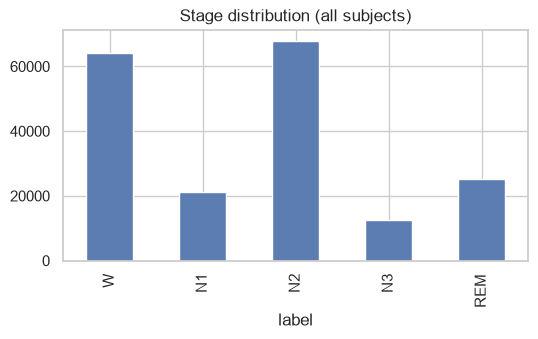

In [9]:
FEATURES_BASE = sw.feature_names(CFG)                      # the 16 raw features

def trim_and_label(table):
    """Per recording: trim wake to +/- margin around sleep, then drop movement/unscored (label -1)."""
    margin = int(WAKE_MARGIN_MIN * 60 / CFG["epoch_length_sec"])
    parts = []
    for rid, g in table.groupby("recording_id", sort=False):
        if TRIM_WAKE:
            g = g[sw.trim_wake_mask(g["label"].to_numpy(), margin)]
        parts.append(g[g["label"] >= 0])
    return pd.concat(parts, ignore_index=True)

eda_df = trim_and_label(raw_df)
print(f"Movement/unscored epochs dropped: {(raw_df['label'] < 0).sum():,}")
print(f"After wake trimming (+/-{WAKE_MARGIN_MIN} min): {len(eda_df):,} labelled epochs from {eda_df['subject_id'].nunique()} subjects")

counts = eda_df["label"].map(sw.INT_TO_LABEL).value_counts().reindex(sw.STAGE_NAMES)
summary = pd.DataFrame({"epochs": counts, "percent": (100 * counts / counts.sum()).round(1)})
display(summary)
ax = counts.plot(kind="bar", figsize=(6, 3), color="#5b7db1"); ax.set_title("Stage distribution (all subjects)")
plt.show()

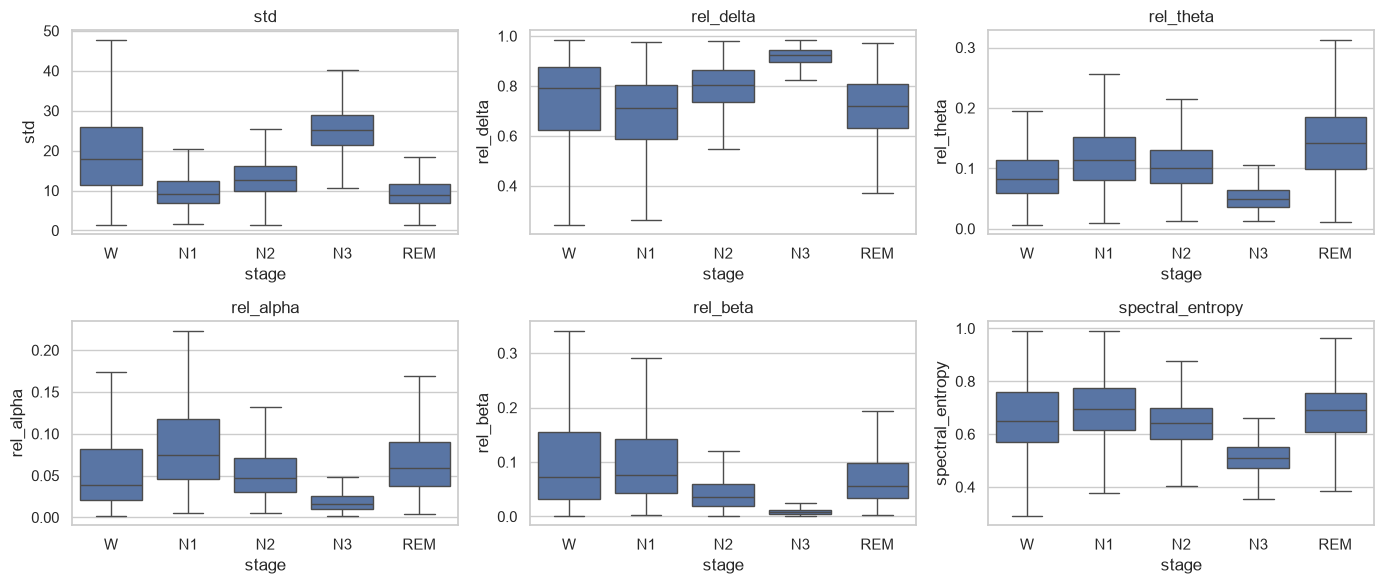

In [10]:
plot_df = eda_df.sample(min(len(eda_df), 40000), random_state=SEED).copy()
plot_df["stage"] = plot_df["label"].map(sw.INT_TO_LABEL)
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for ax, feat in zip(axes.ravel(), ["std", "rel_delta", "rel_theta", "rel_alpha", "rel_beta", "spectral_entropy"]):
    sns.boxplot(data=plot_df, x="stage", y=feat, order=sw.STAGE_NAMES, showfliers=False, ax=ax)
    ax.set_title(feat)
plt.tight_layout(); plt.show()

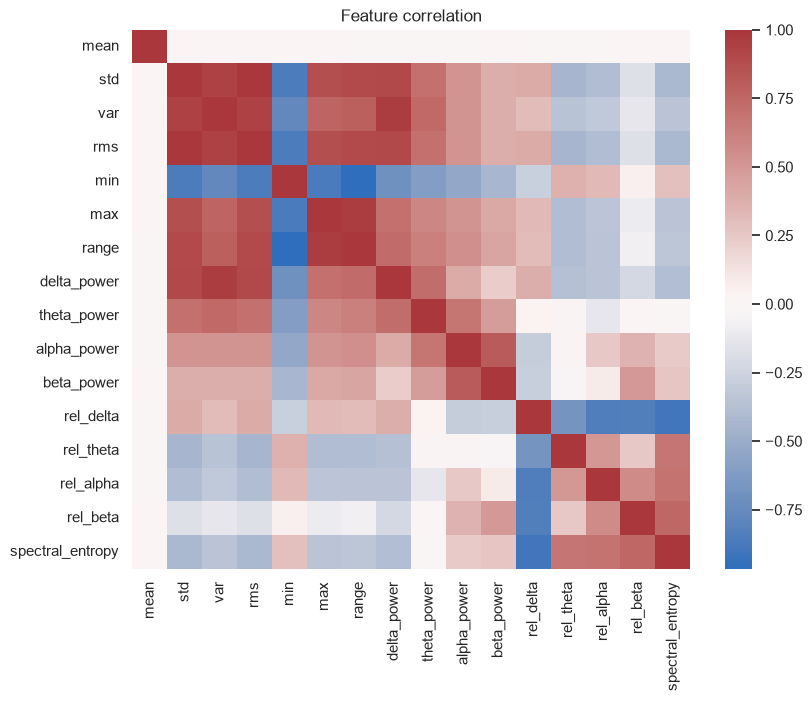

In [11]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(eda_df[FEATURES_BASE].corr(), cmap="vlag", center=0, ax=ax); ax.set_title("Feature correlation")
plt.show()

### 6b. Signal-level EDA
What the raw EEG and its spectrum look like per stage, and how much data each subject contributes.

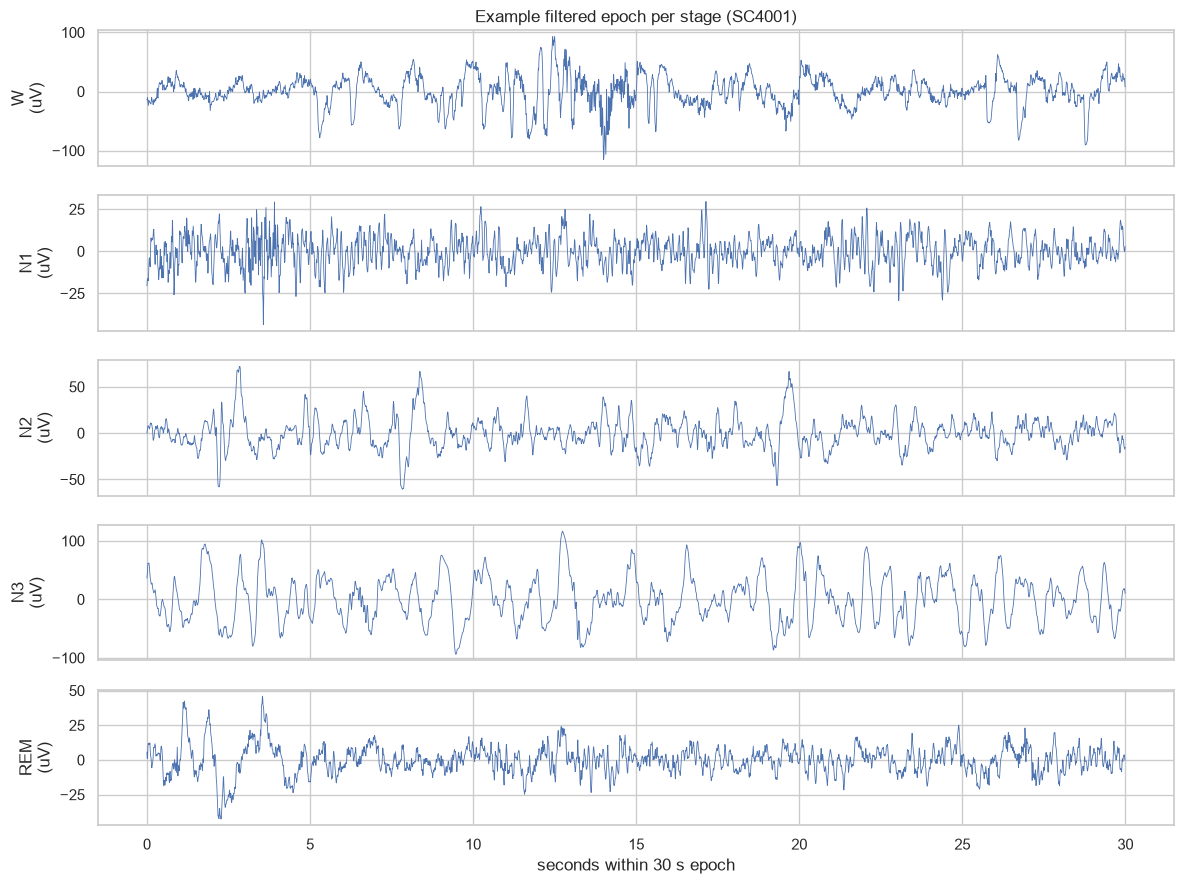

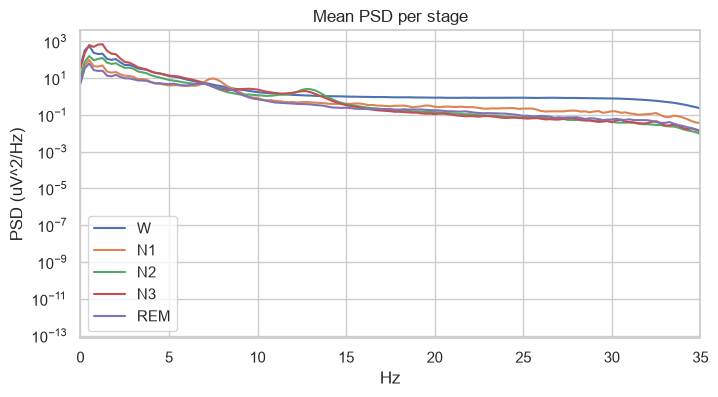

In [12]:
from scipy.signal import welch
r0 = recordings.iloc[0]
ep0, raw_r0 = sw.preprocess_signal(r0.psg, CFG)
on, du, de = sw.read_hypnogram(r0.hyp, raw_r0)
lab0 = sw.epoch_labels_from_annotations(on, du, de, len(ep0), CFG["epoch_length_sec"])
fs = CFG["sampling_rate_hz"]; t = np.arange(ep0.shape[-1]) / fs

fig, axes = plt.subplots(5, 1, figsize=(12, 9), sharex=True)
for ax, s in zip(axes, sw.STAGE_NAMES):
    idx = np.where(lab0 == sw.LABEL_TO_INT[s])[0]
    if len(idx):
        ax.plot(t, ep0[idx[len(idx) // 2], 0], lw=.6)
    ax.set_ylabel(f"{s}\n(uV)")
axes[-1].set_xlabel("seconds within 30 s epoch"); axes[0].set_title(f"Example filtered epoch per stage ({r0.recording_id})")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
for s in sw.STAGE_NAMES:
    idx = np.where(lab0 == sw.LABEL_TO_INT[s])[0]
    if len(idx):
        f, p = welch(ep0[idx, 0], fs=fs, nperseg=400, noverlap=200, axis=-1)
        ax.semilogy(f, p.mean(axis=0), label=s)
ax.set_xlim(0, 35); ax.set_xlabel("Hz"); ax.set_ylabel("PSD (uV^2/Hz)"); ax.legend(); ax.set_title("Mean PSD per stage")
plt.show()

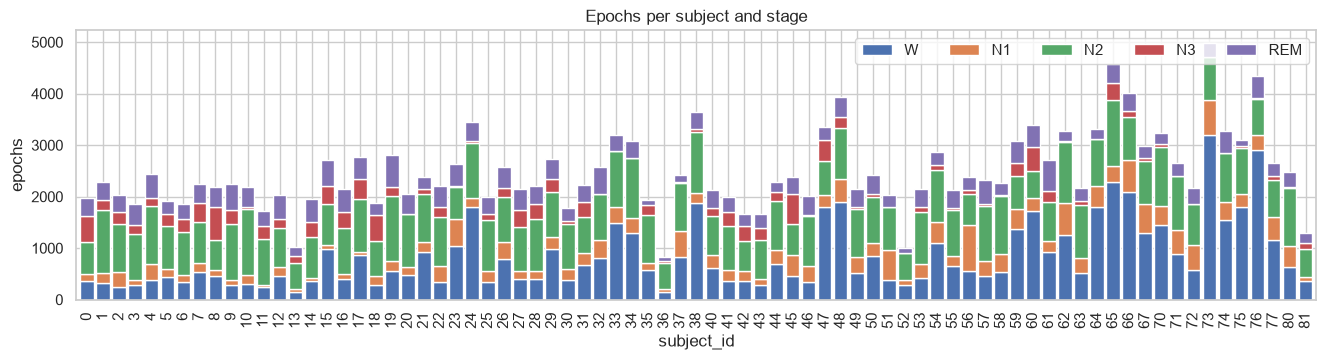

Saved cleaned dataset: cache\clean_epoch_features.csv


In [13]:
per_subj = eda_df.assign(stage=eda_df["label"].map(sw.INT_TO_LABEL)).groupby(["subject_id", "stage"]).size().unstack(fill_value=0)[sw.STAGE_NAMES]
per_subj.plot(kind="bar", stacked=True, figsize=(16, 3.5), width=.85)
plt.title("Epochs per subject and stage"); plt.ylabel("epochs"); plt.legend(loc="upper right", ncol=5)
plt.show()
eda_df.to_csv(CACHE_DIR / "clean_epoch_features.csv", index=False)       # cleaned, labelled (raw-feature) dataset
print("Saved cleaned dataset:", CACHE_DIR / "clean_epoch_features.csv")

## 7. Subject-wise split (70 / 15 / 15)
The split is made on **subject IDs**, so both nights of a subject land in one partition (no leakage between train and test).
The mapping is saved and reused by every model and every feature variant.

In [14]:
subjects = np.array(sorted(raw_df.loc[raw_df["label"] >= 0, "subject_id"].unique()))
rng = np.random.RandomState(SEED); rng.shuffle(subjects)
n = len(subjects)
n_test = max(1, round(0.15 * n)); n_val = max(1, round(0.15 * n))
test_s, val_s, train_s = subjects[:n_test], subjects[n_test:n_test + n_val], subjects[n_test + n_val:]

split = {"seed": SEED, "train": sorted(map(int, train_s)), "val": sorted(map(int, val_s)), "test": sorted(map(int, test_s))}
json.dump(split, open(ARTIFACT_DIR / "subject_split.json", "w"), indent=2)
assert not (set(train_s) & set(val_s)) and not (set(train_s) & set(test_s)) and not (set(val_s) & set(test_s))
print({k: len(v) for k, v in split.items() if k != "seed"}, "subjects")

{'train': 53, 'val': 12, 'test': 12} subjects


## 8. Candidate models and evaluation helpers
Tree models need no scaling. The SVM is wrapped in a pipeline so the scaler is fitted on training data only.
XGBoost and HistGradientBoosting get balanced per-sample weights; labels are integers 0..4.

In [15]:
def make_model(name, **p):
    if name == "Random Forest":
        return RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=SEED, **p)
    if name == "Extra Trees":
        return ExtraTreesClassifier(class_weight="balanced", n_jobs=-1, random_state=SEED, **p)
    if name == "XGBoost":
        return XGBClassifier(objective="multi:softprob", tree_method="hist", n_jobs=-1, random_state=SEED, **p)
    if name == "SVM":
        return make_pipeline(StandardScaler(), SVC(kernel="rbf", class_weight="balanced", probability=False,
                                                   random_state=SEED, **p))
    if name == "HistGradientBoosting":
        return HistGradientBoostingClassifier(random_state=SEED, **p)
    if name == "Majority baseline":
        return DummyClassifier(strategy="most_frequent")
    raise ValueError(name)

def fit_model(name, model, X, y):
    if name == "SVM" and len(X) > SVM_MAX_TRAIN:                      # random subsample for SVM only
        idx = np.random.RandomState(SEED).choice(len(X), SVM_MAX_TRAIN, replace=False)
        X, y = X[idx], y[idx]
    if name in ("XGBoost", "HistGradientBoosting"):
        model.fit(X, y, sample_weight=compute_sample_weight("balanced", y))
    else:
        model.fit(X, y)
    return model

LABELS = list(range(5))
def evaluate(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=LABELS, zero_division=0)
    return {
        "macro_f1": f1_score(y_true, y_pred, average="macro", labels=LABELS, zero_division=0),
        "accuracy": accuracy_score(y_true, y_pred),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted", labels=LABELS, zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, average="macro", labels=LABELS, zero_division=0),
        "n1_recall": r[sw.LABEL_TO_INT["N1"]],
        "per_class": {s: {"precision": p[i], "recall": r[i], "f1": f[i]} for i, s in enumerate(sw.STAGE_NAMES)},
    }

## 9. Feature variants (ablation on validation)
Raw band-power features differ a lot between people, so a model trained on some subjects struggles on new ones.
Two fixes are compared using the same split and the same quick Extra Trees model:

* **A_raw** – the 16 spec features as they are
* **B_zscore** – every feature z-scored *within its own recording* (removes person-to-person amplitude differences)
* **C_zscore_context** – B plus the previous / next 1 and 2 epochs of the key spectral features (stages last minutes, not 30 s)

All transforms are applied per recording on the full night **before** wake trimming, so neighbouring epochs are real neighbours.
Quality screening uses the stored raw amplitudes. Test data is not touched here.

A_raw              val macro F1 = 0.5449   accuracy = 0.6360
B_zscore           val macro F1 = 0.5412   accuracy = 0.6614
C_zscore_context   val macro F1 = 0.5831   accuracy = 0.7041


,variant,n_features,val_macro_f1,val_accuracy,val_n1_recall,sec
0,C_zscore_context,40,0.5831,0.7041,0.0770,13.3233
1,A_raw,16,0.5449,0.6360,0.0826,9.0484
2,B_zscore,16,0.5412,0.6614,0.0567,10.3228


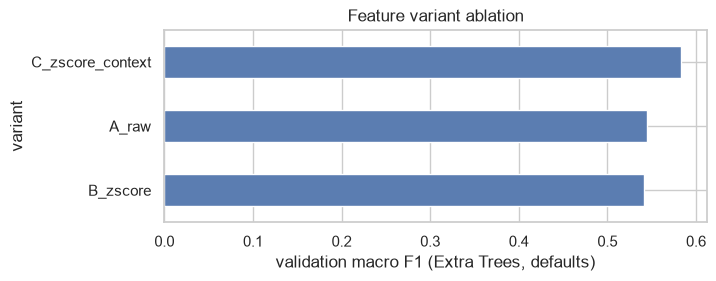

In [16]:
def build_variant(raw, cfg_v):
    parts = [sw.add_recording_features(g.sort_values("epoch_index"), cfg_v)
             for _, g in raw.groupby("recording_id", sort=False)]
    return pd.concat(parts, ignore_index=True)

def prepare_partitions(table):
    d = trim_and_label(table)
    part = lambda ids: d[d["subject_id"].isin(ids)].reset_index(drop=True)
    tr, va, te = part(split["train"]), part(split["val"]), part(split["test"])
    thr = None
    if APPLY_QUALITY:                      # threshold learned on TRAIN only, applied to all partitions
        thr = float(np.quantile(tr["raw_peak"], 0.999))
        ok = lambda x: (x["raw_std"] > FLAT_STD_UV) & (x["raw_peak"] <= thr)
        tr, va, te = [x[ok(x)].reset_index(drop=True) for x in (tr, va, te)]
    return tr, va, te, thr

VARIANTS = {
    "A_raw":            dict(normalize_per_recording=False, context_epochs=False),
    "B_zscore":         dict(normalize_per_recording=True,  context_epochs=False),
    "C_zscore_context": dict(normalize_per_recording=True,  context_epochs=True),
}
tables, prepared, abl_rows = {}, {}, []
for vname, flags in VARIANTS.items():
    cfg_v = {**CFG, **flags}
    tbl = build_variant(raw_df, cfg_v)
    feats = sw.model_feature_names(cfg_v)
    tr, va, te, thr = prepare_partitions(tbl)
    tables[vname] = tbl; prepared[vname] = (tr, va, te, thr, feats, flags)
    t0 = time.time()
    m = fit_model("Extra Trees", make_model("Extra Trees", n_estimators=200), tr[feats].to_numpy(), tr["label"].to_numpy())
    ev = evaluate(va["label"].to_numpy(), m.predict(va[feats].to_numpy()))
    abl_rows.append({"variant": vname, "n_features": len(feats), "val_macro_f1": ev["macro_f1"],
                     "val_accuracy": ev["accuracy"], "val_n1_recall": ev["n1_recall"], "sec": time.time() - t0})
    print(f"{vname:18s} val macro F1 = {ev['macro_f1']:.4f}   accuracy = {ev['accuracy']:.4f}")

ablation = pd.DataFrame(abl_rows).sort_values("val_macro_f1", ascending=False).reset_index(drop=True)
ablation.to_csv(ARTIFACT_DIR / "feature_ablation.csv", index=False)
display(ablation.round(4))
ax = ablation.set_index("variant")["val_macro_f1"].plot(kind="barh", figsize=(7, 2.5), color="#5b7db1")
ax.invert_yaxis(); ax.set_xlabel("validation macro F1 (Extra Trees, defaults)"); ax.set_title("Feature variant ablation")
plt.show()

In [17]:
CHOSEN = FEATURE_VARIANT or ablation.loc[0, "variant"]
train_df, val_df, test_df, QUALITY_THR, FEATURES, chosen_flags = prepared[CHOSEN]
CFG.update(chosen_flags)
CFG["quality"]["max_abs_uv"] = QUALITY_THR
full_tbl = tables[CHOSEN]                                   # full-night table of the chosen variant (for the parity check)

X_train, y_train = train_df[FEATURES].to_numpy(), train_df["label"].to_numpy()
X_val,   y_val   = val_df[FEATURES].to_numpy(),   val_df["label"].to_numpy()
X_test,  y_test  = test_df[FEATURES].to_numpy(),  test_df["label"].to_numpy()
print(f"Chosen feature variant: {CHOSEN}  ({len(FEATURES)} features)  flags={chosen_flags}")
print(f"Quality screen: flat std < {FLAT_STD_UV} uV or |amp| > {QUALITY_THR if QUALITY_THR is None else round(QUALITY_THR)} uV removed")
print("epochs  train / val / test:", X_train.shape[0], X_val.shape[0], X_test.shape[0])

Chosen feature variant: C_zscore_context  (40 features)  flags={'normalize_per_recording': True, 'context_epochs': True}
Quality screen: flat std < 1.0 uV or |amp| > 197 uV removed
epochs  train / val / test: 133512 27625 29827


## 10. Compare all candidates with default settings (train → validation)

In [18]:
DEFAULTS = {
    "Majority baseline": {},
    "Random Forest": {"n_estimators": 200},
    "Extra Trees": {"n_estimators": 200},
    "XGBoost": {"n_estimators": 200, "max_depth": 5, "learning_rate": 0.1},
    "SVM": {},
    "HistGradientBoosting": {},
}
rows, fitted = [], {}
for name, params in DEFAULTS.items():
    t0 = time.time(); m = fit_model(name, make_model(name, **params), X_train, y_train); t_fit = time.time() - t0
    t0 = time.time(); pred = m.predict(X_val); t_pred = time.time() - t0
    ev = evaluate(y_val, pred); fitted[name] = m
    rows.append({"model": name, **{k: ev[k] for k in ["macro_f1", "accuracy", "weighted_f1", "macro_recall", "n1_recall"]},
                 "train_sec": t_fit, "predict_sec": t_pred})
    print(f"{name:22s} macro_f1={ev['macro_f1']:.4f}  ({t_fit:.0f}s)")
default_results = pd.DataFrame(rows).sort_values("macro_f1", ascending=False).reset_index(drop=True)
default_results.round(4)

Majority baseline      macro_f1=0.0869  (0s)
Random Forest          macro_f1=0.6131  (30s)
Extra Trees            macro_f1=0.5831  (12s)
XGBoost                macro_f1=0.6351  (10s)
SVM                    macro_f1=0.6312  (16s)
HistGradientBoosting   macro_f1=0.6325  (19s)


,model,macro_f1,accuracy,weighted_f1,macro_recall,n1_recall,train_sec,predict_sec
0,XGBoost,0.6351,0.6686,0.6839,0.6589,0.3774,9.6222,0.0822
1,HistGradientBoosting,0.6325,0.6667,0.6824,0.6533,0.3815,19.1266,0.1701
2,SVM,0.6312,0.6651,0.6768,0.6613,0.3751,16.3098,28.6498
3,Random Forest,0.6131,0.6774,0.6779,0.6131,0.2400,29.8712,0.2989
4,Extra Trees,0.5831,0.7041,0.6764,0.5728,0.0770,11.8952,0.4490
5,Majority baseline,0.0869,0.2774,0.1204,0.2000,0.0000,0.2277,0.0010


## 11. Tune the strongest candidates
Random Forest and XGBoost are always tuned; the top-`TUNE_TOP_K` default models are added. Each trial is trained on the
training subjects and scored on validation **macro F1**. The search is a seeded random sample of the grid (`N_TUNING_TRIALS`).

In [19]:
GRIDS = {
    "Random Forest": {"n_estimators": [200, 300], "max_depth": [None, 20, 40],
                      "min_samples_leaf": [1, 2, 4], "max_features": ["sqrt", 0.3]},
    "Extra Trees":   {"n_estimators": [200, 300], "max_depth": [None, 20, 40],
                      "min_samples_leaf": [1, 2, 4], "max_features": ["sqrt", 0.3]},
    "XGBoost":       {"n_estimators": [200, 300], "max_depth": [3, 5, 7],
                      "learning_rate": [0.03, 0.1], "subsample": [0.8, 1.0]},
    "SVM":           {"svc__C": [0.1, 1, 10], "svc__gamma": ["scale", 0.01]},
    "HistGradientBoosting": {"learning_rate": [0.05, 0.1], "max_depth": [None, 6], "max_iter": [200, 300]},
}
cands = set(["Random Forest", "XGBoost"]) | set(
    m for m in default_results["model"].head(TUNE_TOP_K + 1) if m in GRIDS)
print("Tuning:", sorted(cands))

def build_tuned(name, params):
    if name == "SVM":
        return make_pipeline(StandardScaler(), SVC(kernel="rbf", class_weight="balanced", random_state=SEED,
                                                   C=params["svc__C"], gamma=params["svc__gamma"]))
    return make_model(name, **params)

trials = []
for name in sorted(cands):
    grid_size = int(np.prod([len(v) for v in GRIDS[name].values()]))
    sampler = ParameterSampler(GRIDS[name], n_iter=min(N_TUNING_TRIALS, grid_size), random_state=SEED)
    for params in sampler:
        t0 = time.time(); m = fit_model(name, build_tuned(name, params), X_train, y_train); t_fit = time.time() - t0
        t0 = time.time(); pred = m.predict(X_val); t_pred = time.time() - t0
        ev = evaluate(y_val, pred)
        trials.append({"model": name, "params": params, "macro_f1": ev["macro_f1"], "n1_recall": ev["n1_recall"],
                       "accuracy": ev["accuracy"], "train_sec": t_fit, "predict_sec": t_pred})
        print(f"{name:22s} macro_f1={ev['macro_f1']:.4f}  ({t_fit:.0f}s)  {params}")
tuning = pd.DataFrame(trials).sort_values("macro_f1", ascending=False).reset_index(drop=True)

Tuning: ['HistGradientBoosting', 'Random Forest', 'SVM', 'XGBoost']
HistGradientBoosting   macro_f1=0.6351  (28s)  {'max_iter': 300, 'max_depth': None, 'learning_rate': 0.05}
HistGradientBoosting   macro_f1=0.6334  (25s)  {'max_iter': 300, 'max_depth': None, 'learning_rate': 0.1}
HistGradientBoosting   macro_f1=0.6339  (28s)  {'max_iter': 200, 'max_depth': None, 'learning_rate': 0.05}
HistGradientBoosting   macro_f1=0.6359  (44s)  {'max_iter': 300, 'max_depth': 6, 'learning_rate': 0.1}
HistGradientBoosting   macro_f1=0.6365  (36s)  {'max_iter': 200, 'max_depth': 6, 'learning_rate': 0.05}
HistGradientBoosting   macro_f1=0.6325  (43s)  {'max_iter': 200, 'max_depth': None, 'learning_rate': 0.1}
Random Forest          macro_f1=0.6179  (132s)  {'n_estimators': 300, 'min_samples_leaf': 4, 'max_features': 0.3, 'max_depth': 40}
Random Forest          macro_f1=0.6190  (51s)  {'n_estimators': 300, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 20}
Random Forest          macro_f1=0.6

## 12. Select the final model
Highest validation macro F1; ties (within 0.001) broken by N1 recall, then runtime.

In [21]:
pool = tuning.copy()
# include the untuned defaults so a default can win if tuning did not help
for _, r in default_results.iterrows():
    if r["model"] in cands:
        pool = pd.concat([pool, pd.DataFrame([{"model": r["model"], "params": DEFAULTS[r["model"]], "macro_f1": r["macro_f1"],
                          "n1_recall": r["n1_recall"], "accuracy": r["accuracy"], "train_sec": r["train_sec"],
                          "predict_sec": r["predict_sec"]}])], ignore_index=True)
pool["f1_bin"] = (pool["macro_f1"] / 0.001).round()
pool = pool.sort_values(["f1_bin", "n1_recall", "predict_sec"], ascending=[False, False, True]).reset_index(drop=True)
best = pool.iloc[0]
BEST_NAME, BEST_PARAMS = best["model"], best["params"]
print(f"Selected: {BEST_NAME}  validation macro F1 = {best['macro_f1']:.4f}\nParams: {BEST_PARAMS}")
pool.drop(columns="f1_bin").head(10).round(4)

Selected: SVM  validation macro F1 = 0.6401
Params: {'svc__gamma': 0.01, 'svc__C': 10}


,model,params,macro_f1,n1_recall,accuracy,train_sec,predict_sec
0,SVM,"{'svc__gamma': 0.01, 'svc__C': 10}",0.6401,0.3770,0.6771,20.5175,39.3862
1,XGBoost,"{'subsample': 0.8, 'n_estimators': 300, 'max_d...",0.6393,0.3736,0.6750,18.1788,0.1535
2,HistGradientBoosting,"{'max_iter': 200, 'max_depth': 6, 'learning_ra...",0.6365,0.3808,0.6709,36.3456,0.6457
3,SVM,"{'svc__gamma': 'scale', 'svc__C': 10}",0.6372,0.3323,0.6819,14.7968,26.6953
4,HistGradientBoosting,"{'max_iter': 300, 'max_depth': 6, 'learning_ra...",0.6359,0.3417,0.6790,44.2310,0.8421
5,XGBoost,"{'n_estimators': 200, 'max_depth': 5, 'learnin...",0.6351,0.3774,0.6686,9.6222,0.0822
6,XGBoost,"{'subsample': 0.8, 'n_estimators': 200, 'max_d...",0.6349,0.3751,0.6691,9.9197,0.0710
7,HistGradientBoosting,"{'max_iter': 300, 'max_depth': None, 'learning...",0.6351,0.3639,0.6726,27.5314,0.4165
8,HistGradientBoosting,"{'max_iter': 200, 'max_depth': None, 'learning...",0.6339,0.3766,0.6681,28.1324,0.5368
9,HistGradientBoosting,{},0.6325,0.3815,0.6667,19.1266,0.1701


### 12b. Model analysis table
One row per model: default vs best-tuned validation scores, runtime, chosen hyperparameters, and which one was selected.
Saved to `artifacts/model_comparison.csv`.

,default_macro_f1,default_accuracy,default_n1_recall,default_train_sec,default_predict_sec,tuned_macro_f1,tuned_accuracy,tuned_n1_recall,tuned_train_sec,best_params,val_macro_f1_final,selected
model,,,,,,,,,,,,
SVM,0.6312,0.6651,0.3751,16.3098,28.6498,0.6401,0.6771,0.3770,20.5175,"{'svc__gamma': 0.01, 'svc__C': 10}",0.6401,True
XGBoost,0.6351,0.6686,0.3774,9.6222,0.0822,0.6393,0.6750,0.3736,18.1788,"{'subsample': 0.8, 'n_estimators': 300, 'max_d...",0.6393,False
HistGradientBoosting,0.6325,0.6667,0.3815,19.1266,0.1701,0.6365,0.6709,0.3808,36.3456,"{'max_iter': 200, 'max_depth': 6, 'learning_ra...",0.6365,False
Random Forest,0.6131,0.6774,0.2400,29.8712,0.2989,0.6198,0.6654,0.3060,30.3063,"{'n_estimators': 200, 'min_samples_leaf': 4, '...",0.6198,False
Extra Trees,0.5831,0.7041,0.0770,11.8952,0.4490,NaN,NaN,NaN,NaN,NaN,0.5831,False
Majority baseline,0.0869,0.2774,0.0000,0.2277,0.0010,NaN,NaN,NaN,NaN,NaN,0.0869,False


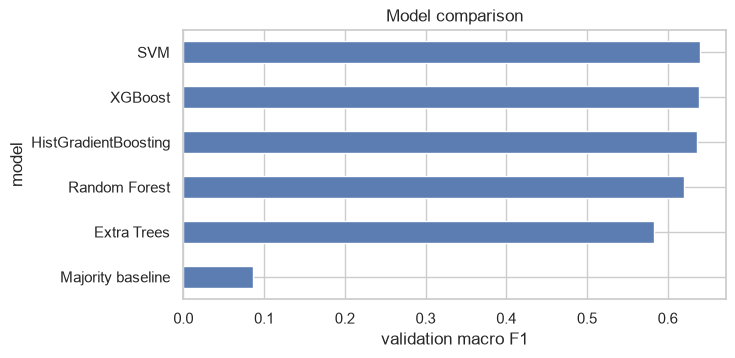

In [22]:
best_tuned = tuning.sort_values("macro_f1", ascending=False).groupby("model").head(1).set_index("model")
analysis = default_results.set_index("model")[["macro_f1", "accuracy", "n1_recall", "train_sec", "predict_sec"]].add_prefix("default_")
analysis["tuned_macro_f1"] = best_tuned["macro_f1"]
analysis["tuned_accuracy"] = best_tuned["accuracy"]
analysis["tuned_n1_recall"] = best_tuned["n1_recall"]
analysis["tuned_train_sec"] = best_tuned["train_sec"]
analysis["best_params"] = best_tuned["params"].astype(str)
analysis["val_macro_f1_final"] = analysis[["default_macro_f1", "tuned_macro_f1"]].max(axis=1)
analysis["selected"] = analysis.index == BEST_NAME
analysis = analysis.sort_values("val_macro_f1_final", ascending=False)
analysis.to_csv(ARTIFACT_DIR / "model_comparison.csv")
display(analysis.round(4))

ax = analysis["val_macro_f1_final"].plot(kind="barh", figsize=(7, 3.5), color="#5b7db1")
ax.invert_yaxis(); ax.set_xlabel("validation macro F1"); ax.set_title("Model comparison")
plt.show()

## 13. Final fit and one-shot test evaluation
Optionally refit on train + validation subjects with the chosen hyperparameters, then evaluate on the held-out **test**
subjects **once**. No choices are made from test results.

In [23]:
if REFIT_TRAIN_VAL:
    X_fit, y_fit = np.vstack([X_train, X_val]), np.concatenate([y_train, y_val])
else:
    X_fit, y_fit = X_train, y_train
final_model = fit_model(BEST_NAME, build_tuned(BEST_NAME, BEST_PARAMS), X_fit, y_fit)

t0 = time.time(); pred_test = final_model.predict(X_test); t_pred = time.time() - t0
test_eval = evaluate(y_test, pred_test)
kappa = cohen_kappa_score(y_test, pred_test)
print(f"TEST  macro F1 = {test_eval['macro_f1']:.4f} | accuracy = {test_eval['accuracy']:.4f} | "
      f"weighted F1 = {test_eval['weighted_f1']:.4f} | macro recall = {test_eval['macro_recall']:.4f} | "
      f"N1 recall = {test_eval['n1_recall']:.4f} | kappa = {kappa:.3f}")
print(f"Inference: {1000 * t_pred / len(X_test):.3f} ms/epoch")
print(classification_report(y_test, pred_test, labels=LABELS, target_names=sw.STAGE_NAMES, zero_division=0, digits=3))

TEST  macro F1 = 0.6570 | accuracy = 0.6893 | weighted F1 = 0.6999 | macro recall = 0.7158 | N1 recall = 0.5002 | kappa = 0.590
Inference: 1.426 ms/epoch
              precision    recall  f1-score   support

           W      0.898     0.757     0.822      9020
          N1      0.390     0.500     0.438      4148
          N2      0.803     0.644     0.715     11351
          N3      0.482     0.894     0.626      1677
         REM      0.607     0.783     0.684      3631

    accuracy                          0.689     29827
   macro avg      0.636     0.716     0.657     29827
weighted avg      0.732     0.689     0.700     29827



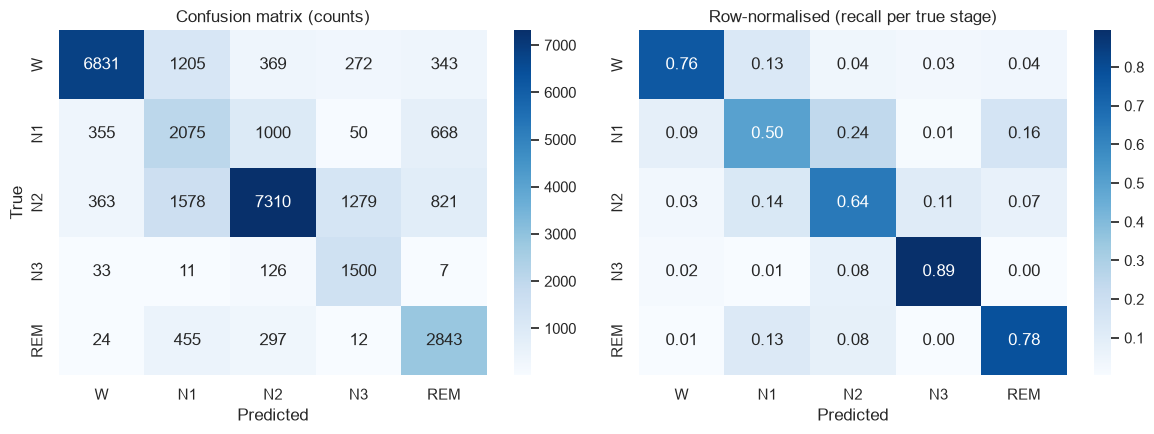

In [24]:
cm = confusion_matrix(y_test, pred_test, labels=LABELS)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=sw.STAGE_NAMES, yticklabels=sw.STAGE_NAMES, ax=axes[0])
axes[0].set_title("Confusion matrix (counts)"); axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("True")
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".2f", cmap="Blues",
            xticklabels=sw.STAGE_NAMES, yticklabels=sw.STAGE_NAMES, ax=axes[1])
axes[1].set_title("Row-normalised (recall per true stage)"); axes[1].set_xlabel("Predicted")
plt.tight_layout(); plt.show()

In [25]:
# How consistent is the model across unseen people? One row per held-out recording.
rows = []
for rid, g in test_df.groupby("recording_id"):
    p = final_model.predict(g[FEATURES].to_numpy())
    present = np.unique(g["label"])
    rows.append({"recording": rid, "subject": int(g["subject_id"].iloc[0]), "epochs": len(g),
                 "accuracy": accuracy_score(g["label"], p),
                 "macro_f1": f1_score(g["label"], p, average="macro", labels=present, zero_division=0)})
per_rec = pd.DataFrame(rows).sort_values("macro_f1")
per_rec.to_csv(ARTIFACT_DIR / "test_per_recording_metrics.csv", index=False)
print(f"Per-recording test accuracy: {per_rec['accuracy'].mean():.3f} +/- {per_rec['accuracy'].std():.3f}   "
      f"macro F1: {per_rec['macro_f1'].mean():.3f} +/- {per_rec['macro_f1'].std():.3f}  ({len(per_rec)} recordings)")
per_rec.round(3)

Per-recording test accuracy: 0.680 +/- 0.087   macro F1: 0.607 +/- 0.098  (24 recordings)


,recording,subject,epochs,accuracy,macro_f1
22,SC4771,77,1318,0.560,0.443
4,SC4101,10,1104,0.556,0.454
20,SC4711,71,1405,0.673,0.497
15,SC4512,51,954,0.628,0.504
8,SC4351,35,976,0.585,0.531
9,SC4352,35,963,0.618,0.550
2,SC4041,4,1235,0.543,0.552
14,SC4511,51,1087,0.647,0.557
16,SC4541,54,1716,0.753,0.559
17,SC4542,54,1146,0.624,0.567


In [26]:
# Feature importance (tree models) or permutation importance on validation (SVM)
est = final_model
if hasattr(est, "feature_importances_"):
    imp = pd.Series(est.feature_importances_, index=FEATURES)
else:
    from sklearn.inspection import permutation_importance
    r = permutation_importance(est, X_val, y_val, scoring="f1_macro", n_repeats=3, random_state=SEED)
    imp = pd.Series(r.importances_mean, index=FEATURES)
imp.sort_values().tail(20).plot(kind="barh", figsize=(7, 6), color="#5b7db1"); plt.title(f"Top 20 feature importances - {BEST_NAME}")
plt.tight_layout(); plt.show()

KeyboardInterrupt: 

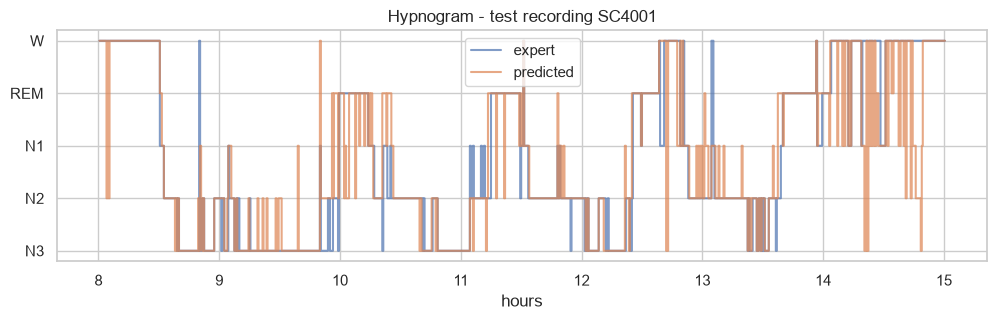

In [27]:
# Predicted vs true hypnogram for one test recording
rid = test_df["recording_id"].iloc[0]
g = test_df[test_df["recording_id"] == rid]
p = final_model.predict(g[FEATURES].to_numpy())
order = {0: 4, 4: 3, 1: 2, 2: 1, 3: 0}        # W, REM, N1, N2, N3 from top to bottom
fig, ax = plt.subplots(figsize=(12, 3))
ax.step(g["epoch_index"] * 0.5 / 60, [order[v] for v in g["label"]], where="post", label="expert", alpha=.7)
ax.step(g["epoch_index"] * 0.5 / 60, [order[v] for v in p], where="post", label="predicted", alpha=.7)
ax.set_yticks([0, 1, 2, 3, 4]); ax.set_yticklabels(["N3", "N2", "N1", "REM", "W"]); ax.set_xlabel("hours"); ax.legend()
ax.set_title(f"Hypnogram - test recording {rid}"); plt.show()

In [28]:
per_class = pd.DataFrame(test_eval["per_class"]).T.round(4)
per_class["support"] = np.bincount(y_test, minlength=5)
per_class.to_csv(ARTIFACT_DIR / "test_per_class_metrics.csv")
display(per_class)

,precision,recall,f1,support
W,0.8981,0.7573,0.8217,9020
N1,0.3897,0.5002,0.4381,4148
N2,0.8031,0.6440,0.7148,11351
N3,0.4819,0.8945,0.6263,1677
REM,0.6072,0.7830,0.6840,3631


## 14. Save artifacts
Writes `best_model.joblib`, `feature_names.json`, `label_mapping.json`, `preprocessing_config.json`,
`evaluation_metrics.json`, plus the subject split, the ablation / comparison tables and a `requirements.txt`.
`preprocessing_config.json` now also records `normalize_per_recording` and `context_epochs`, which the backend must apply
with `slumberwell_core.add_recording_features`.

In [29]:
joblib.dump(final_model, ARTIFACT_DIR / "best_model.joblib")
json.dump(FEATURES, open(ARTIFACT_DIR / "feature_names.json", "w"), indent=2)
json.dump(sw.INT_TO_LABEL, open(ARTIFACT_DIR / "label_mapping.json", "w"), indent=2)
json.dump(CFG, open(ARTIFACT_DIR / "preprocessing_config.json", "w"), indent=2)

def clean(o):
    if isinstance(o, dict):  return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.integer,)):  return int(o)
    return o

val_pred = final_model.predict(X_val)
versions = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "scipy": scipy.__version__, "scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__,
            "mne": mne.__version__, "joblib": joblib.__version__}
metrics = clean({
    "model_name": BEST_NAME, "hyperparameters": BEST_PARAMS, "refit_on_train_plus_val": REFIT_TRAIN_VAL,
    "feature_variant": CHOSEN, "feature_ablation": ablation.to_dict("records"),
    "validation": {"macro_f1_of_selection_run": best["macro_f1"]},
    "validation_final_model": evaluate(y_val, val_pred) if not REFIT_TRAIN_VAL else "not reported (val used in refit)",
    "test": {**test_eval, "cohen_kappa": kappa, "confusion_matrix": cm.tolist(),
             "inference_ms_per_epoch": 1000 * t_pred / len(X_test),
             "per_recording_accuracy_mean": per_rec["accuracy"].mean(), "per_recording_accuracy_std": per_rec["accuracy"].std(),
             "per_recording_macro_f1_mean": per_rec["macro_f1"].mean(), "per_recording_macro_f1_std": per_rec["macro_f1"].std()},
    "model_comparison_validation": default_results.to_dict("records"),
    "tuning_trials": tuning.to_dict("records"),
    "split": {"seed": SEED, "n_subjects": {k: len(v) for k, v in split.items() if k != "seed"},
              "n_epochs": {"train": len(train_df), "val": len(val_df), "test": len(test_df)}},
    "class_names": sw.STAGE_NAMES, "library_versions": versions,
})
json.dump(metrics, open(ARTIFACT_DIR / "evaluation_metrics.json", "w"), indent=2)
Path(ARTIFACT_DIR / "requirements.txt").write_text(
    "\n".join(f"{k}=={v}" for k, v in versions.items() if k != "python") + "\n")
print("Saved:", sorted(p.name for p in ARTIFACT_DIR.iterdir()))

Saved: ['best_model.joblib', 'evaluation_metrics.json', 'feature_ablation.csv', 'feature_names.json', 'label_mapping.json', 'model_comparison.csv', 'preprocessing_config.json', 'requirements.txt', 'subject_split.json', 'test_per_class_metrics.csv', 'test_per_recording_metrics.csv']


## 15. Inference sanity check (training/serving parity)
Reload the artifacts and run the **inference path** (`featurize_edf` → `add_recording_features`: EDF only, no hypnogram) on a
test-subject recording. Features must match those used in training for the same epochs, and predictions must be reproducible.
This is the same code path the FastAPI backend will use.

In [30]:
model = joblib.load(ARTIFACT_DIR / "best_model.joblib")
feat_names = json.load(open(ARTIFACT_DIR / "feature_names.json"))
cfg_loaded = json.load(open(ARTIFACT_DIR / "preprocessing_config.json"))
labmap = {int(k): v for k, v in json.load(open(ARTIFACT_DIR / "label_mapping.json")).items()}

test_rec = recordings[recordings["subject"].isin(split["test"])].iloc[0]
X_inf = sw.add_recording_features(sw.featurize_edf(test_rec.psg, cfg_loaded), cfg_loaded)[feat_names]
stages = [labmap[i] for i in model.predict(X_inf.to_numpy())]

# parity: inference features == training-table features for the same epochs
ref = full_tbl[full_tbl["recording_id"] == test_rec.recording_id].set_index("epoch_index")[feat_names]
common = ref.index.intersection(X_inf.index)
print("max |feature difference| vs training table:", float(np.abs(ref.loc[common].to_numpy() - X_inf.loc[common].to_numpy()).max()))

print(f"{test_rec.recording_id}: {len(stages)} epochs (whole night, including the long wake periods that training trimmed)")
print(json.dumps(sw.summarize_predictions(stages), indent=2))

max |feature difference| vs training table: 0.0
SC4001: 2650 epochs (whole night, including the long wake periods that training trimmed)
{
  "total_recording_min": 1325.0,
  "total_sleep_min": 366.0,
  "sleep_efficiency_pct": 27.62264150943396,
  "sleep_onset_latency_min": 2.5,
  "rem_latency_min": 0.0,
  "stage_counts": {
    "W": 1918,
    "N1": 87,
    "N2": 281,
    "N3": 215,
    "REM": 149
  },
  "stage_percent": {
    "W": 72.37735849056604,
    "N1": 3.2830188679245285,
    "N2": 10.60377358490566,
    "N3": 8.11320754716981,
    "REM": 5.622641509433962
  }
}


In [31]:
# Get 3 actual examples from your existing test set

import pandas as pd

demo = X_test.copy()
demo["Actual Sleep Stage"] = y_test

# One example each from Wake, N2, and N3
for stage in ["W", "N2", "N3"]:
    if stage in demo["Actual Sleep Stage"].values:
        row = demo[demo["Actual Sleep Stage"] == stage].iloc[[0]]
        print(f"\n{'='*40}")
        print(f"ACTUAL SLEEP STAGE: {stage}")
        print(row.T)

IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices

## Notes and next steps
- **Report the right number:** the test numbers are one-shot on subjects the model never saw; the validation scores were used for choosing.
  The per-recording mean +/- std shows how much the result varies between people.
- **Ablations still worth running:** `TRIM_WAKE` on/off, add `"EEG Pz-Oz"` to `CFG["channels"]`, Hjorth parameters, longer context windows,
  smoothing the predicted hypnogram (stages rarely flip every 30 s).
- **Serving note:** the backend must call `sw.featurize_edf` and then `sw.add_recording_features(..., cfg)` using
  `preprocessing_config.json`; normalisation is computed over the whole uploaded recording.
- **Handoff to Phase 2:** copy `slumberwell_core.py` and the `artifacts/` folder into the backend. Class probabilities from
  `predict_proba` are classifier scores, not calibrated clinical confidence.
- This is a research prototype, not a medical device.